# DAZONE 2026 — INT_RF Random Search 5-Fold CV theo QINI

Notebook này tập trung **duy nhất 1 model: INT_RF**.

Mục tiêu:
- Train **INT_RF — Interaction S-Learner Random Forest**.
- Random search nhiều tổ hợp tham số.
- Đánh giá bằng **5-fold cross-validation**.
- Chọn model tốt nhất theo:

```python
QINI = qini_cash + qini_card
```

Điểm quan trọng cho Kaggle background run:
- Notebook sẽ `print()` đầy đủ từng configuration lên **Logs**.
- Configuration tốt nhất được in rõ dưới tên **A**.
- Sau này có thể tái tạo model bằng cách copy lại dictionary **A** từ Logs.

Cách dùng nhanh:
- Điền `feat_path` và `tgt_path`.
- Chỉnh `RANDOM_SEARCH_N_ITER` nếu muốn chạy nhiều/ít cấu hình hơn.
- Chạy toàn bộ notebook trên Kaggle.


In [1]:
# ============================================================
# 0. MINIMAL ENVIRONMENT SETUP
# ============================================================
# Notebook này chỉ train INT_RF nên không cần causalml.
# Mọi kết quả quan trọng, đặc biệt best config A, sẽ được print ra Kaggle Logs.

print("Environment setup: INT_RF only, no causalml required.", flush=True)


Environment setup: INT_RF only, no causalml required.


In [2]:
# ============================================================
# 1. IMPORTS + GLOBAL CONFIG
# ============================================================
import gc
import os
import re
import time
import json
import random
import warnings
from pathlib import Path

# Giới hạn thread để ổn định runtime trên Kaggle/CPU.
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")

SEED = 42
N_SPLITS = 5
N_JOBS = 4

# ============================================================
# INT_RF RANDOM SEARCH CONFIG
# ============================================================
# RANDOM_SEARCH_N_ITER = số configuration INT_RF được thử.
# Lưu ý: mỗi configuration train 2 target cash/card * 5 folds = 10 RandomForest.
# Tăng giá trị này nếu chạy Kaggle background và muốn search kỹ hơn.
RANDOM_SEARCH_N_ITER = 40


RANDOM_SEARCH_SEED = 2026
RANDOM_SEARCH_VERBOSE_FOLD = True

# Baseline cũ luôn được đưa vào candidate đầu tiên để so sánh.
INT_RF_BASELINE_CONFIG = {
    "n_estimators": 320,
    "max_depth": 9,
    "min_samples_leaf": 80,
    "min_samples_split": 2,
    "max_features": "sqrt",
    "criterion": "gini",
    "class_weight": "balanced_subsample",
    "bootstrap": True,
    "max_samples": None,
    "use_sample_weight": True,
    "pos_weight_multiplier": 1.0,
}

# Không gian random search.
# Các list value để trên một dòng ngang theo format bạn yêu cầu.
INT_RF_RANDOM_SEARCH_SPACE = {
    "n_estimators": [180, 240, 320, 420, 560],
    "max_depth": [6, 8, 9, 10, 12, None],
    "min_samples_leaf": [30, 50, 80, 120, 160],
    "min_samples_split": [2, 20, 50, 100],
    "max_features": ["sqrt", "log2", 0.35, 0.50, 0.75],
    "criterion": ["gini", "entropy"],
    "class_weight": ["balanced_subsample", "balanced", None],
    "bootstrap": [True],
    "max_samples": [None, 0.70, 0.85],
    "use_sample_weight": [True, False],
    "pos_weight_multiplier": [0.60, 0.80, 1.00, 1.20, 1.50],
}

PLOT_TOP_N_MODELS = 5

SELECTED_MODEL_NAMES = ["INT_RF_RANDOM_SEARCH_ONLY"]

print("=" * 100, flush=True)
print("INT_RF Random Search setup", flush=True)
print(f"N_SPLITS={N_SPLITS} | RANDOM_SEARCH_N_ITER={RANDOM_SEARCH_N_ITER} | SEED={SEED}", flush=True)
print("Baseline config:", json.dumps(INT_RF_BASELINE_CONFIG, sort_keys=True, ensure_ascii=False), flush=True)
print("=" * 100, flush=True)


INT_RF Random Search setup
N_SPLITS=5 | RANDOM_SEARCH_N_ITER=40 | SEED=42
Baseline config: {"bootstrap": true, "class_weight": "balanced_subsample", "criterion": "gini", "max_depth": 9, "max_features": "sqrt", "max_samples": null, "min_samples_leaf": 80, "min_samples_split": 2, "n_estimators": 320, "pos_weight_multiplier": 1.0, "use_sample_weight": true}


## 2. Load dữ liệu + feature dropping

In [3]:
# ============================================================
# 2. LOAD DATA + FEATURE DROPPING CONFIG
# ============================================================

FEATURE_DROP_PRIORITY_LIST = [
    "cnt_month_over3_credit_card_6m",
    "cnt_connected_tls",
    "cnt_earlyterminted_pos",
    "min_sign_vol",
    "cli_contact_region_population_grp",
    "cnt_inbound_tls_12m",
    "cnt_bank_inst_appl_12m",
    "f_approve_last_process",
    "worst_credit_status",
    "cli_contact_region_level",
    "cli_education",
    "f_ever_default",
    "cli_age",
    "cli_job",
    "cnt_earlyterminated_cash",
    "amt_terminated_loan_12m",
    "cnt_noinsurance_loan_24m",
    "cnt_report_bank_6m",
    "ratio_conn_tls_endmonth_12m",
    "ratio_conn_tls_weekend_12m",
    "cli_marital_status",
    "avg_sign_vol",
    "cnt_terminated_loan_12m",
    "cnt_fail_tls_3m",
    "last_offer_limit",
    "cli_emp_period",
    "cnt_fi_inst_appl_12m",
    "cnt_total_payment",
    "risk_grp",
    "cnt_lender_has2pay_last_24m",
    "cnt_month_status1",
    "last_process_channel",
    "cnt_month_from_last_appl",
    "cnt_report_institution_12m",
]

# Tùy chỉnh feature dropping:
#   None -> baseline, không drop feature nào.
#   int  -> drop 1 feature theo ID. Ví dụ: COL_IDX = 0.
#   list/tuple/set/range -> drop nhiều feature. Ví dụ: COL_IDX = [2, 3, 4, 5].
#   list(range(a, b)) -> drop liên tiếp ID a..b-1. Ví dụ: list(range(2, 6)) = 2,3,4,5.
#   string "a:b" -> drop liên tiếp ID a..b-1. Ví dụ: "2:6" = 2,3,4,5.
#   string/list tên feature -> drop trực tiếp theo tên feature gốc. Ví dụ: ["cli_age", "risk_grp"].
#
# Ví dụ chạy:
#   COL_IDX = None
#   COL_IDX = 0
#   COL_IDX = [2, 3]
#   COL_IDX = list(range(2, 6))
#   COL_IDX = "2:6"
COL_IDX = None

feat_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_feature.csv"
tgt_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_target.csv"

TARGET_CASH = "cash_sign_30d"
TARGET_CARD = "card_sign_30d"
TREAT_COL_BINARY = "treatment_cash"
TREAT_COL_RAW = "treatment"
ID_CANDIDATES = ["id", "ID", "row_id", "customer_id", "Customer_ID", "client_id", "cli_id", "app_id", "application_id"]




def normalize_feature_drop_selection(selection):
    """Chuẩn hóa cấu hình drop feature.

    Trả về:
    - drop_ids: list ID trong FEATURE_DROP_PRIORITY_LIST.
    - drop_base_cols: list tên feature gốc cần drop.

    Hỗ trợ:
    - None
    - int
    - list/tuple/set/range chứa int hoặc tên feature
    - string "a:b" để drop ID a..b-1
    - string tên feature gốc
    """
    if selection is None:
        return [], []

    def _expand_one(item):
        if isinstance(item, str):
            s = item.strip()
            if not s:
                return []
            if re.fullmatch(r"\d+", s):
                return [int(s)]
            m = re.fullmatch(r"(\d+)\s*:\s*(\d+)", s)
            if m:
                start, stop = int(m.group(1)), int(m.group(2))
                return list(range(start, stop))
            return [s]
        if isinstance(item, (int, np.integer)):
            return [int(item)]
        if isinstance(item, range):
            return list(item)
        if isinstance(item, slice):
            start = 0 if item.start is None else item.start
            stop = len(FEATURE_DROP_PRIORITY_LIST) if item.stop is None else item.stop
            step = 1 if item.step is None else item.step
            return list(range(start, stop, step))
        raise TypeError(
            "COL_IDX chỉ hỗ trợ None, int, range, slice, str, "
            "hoặc list/tuple/set chứa int/tên feature."
        )

    if isinstance(selection, (list, tuple, set, range, np.ndarray, pd.Series)):
        raw_items = []
        for item in list(selection):
            raw_items.extend(_expand_one(item))
    else:
        raw_items = _expand_one(selection)

    drop_ids = []
    drop_base_cols = []
    seen_cols = set()

    for item in raw_items:
        if isinstance(item, (int, np.integer)):
            idx = int(item)
            if idx < 0 or idx >= len(FEATURE_DROP_PRIORITY_LIST):
                raise IndexError(f"COL_IDX={idx} ngoài range 0..{len(FEATURE_DROP_PRIORITY_LIST)-1}")
            base_col = FEATURE_DROP_PRIORITY_LIST[idx]
            if base_col not in seen_cols:
                drop_ids.append(idx)
                drop_base_cols.append(base_col)
                seen_cols.add(base_col)
        elif isinstance(item, str):
            base_col = item.strip()
            if base_col not in FEATURE_DROP_PRIORITY_LIST:
                print(f"WARNING: '{base_col}' không nằm trong FEATURE_DROP_PRIORITY_LIST, vẫn sẽ thử match trong df_feature.")
                idx = None
            else:
                idx = FEATURE_DROP_PRIORITY_LIST.index(base_col)
            if base_col not in seen_cols:
                drop_ids.append(idx)
                drop_base_cols.append(base_col)
                seen_cols.add(base_col)
        else:
            raise TypeError(f"COL_IDX chứa phần tử không hợp lệ: {item!r}")

    return drop_ids, drop_base_cols


def match_base_feature_columns(columns, base_col):
    """Match cột gốc và các cột one-hot/encoded sinh ra từ feature gốc."""
    if base_col is None:
        return []
    return [c for c in columns if c == base_col or c.startswith(f"{base_col}_")]


def make_id_series(source_df, n_rows=None, id_col=None):
    if n_rows is None:
        n_rows = len(source_df)
    if id_col is not None and id_col in source_df.columns:
        return source_df[id_col].reset_index(drop=True).rename(id_col)
    return pd.Series(np.arange(n_rows), name="row_id")


def encode_treatment_cash(feature_df):
    """Return W: 1 = Cash strategy, 0 = Card strategy."""
    if TREAT_COL_BINARY in feature_df.columns:
        return feature_df[TREAT_COL_BINARY].astype(int).to_numpy(), TREAT_COL_BINARY
    if TREAT_COL_RAW not in feature_df.columns:
        raise ValueError("Thiếu cột treatment_cash hoặc treatment trong df_feature.csv")

    s = feature_df[TREAT_COL_RAW]
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(int).to_numpy(), TREAT_COL_RAW

    st = s.astype(str).str.strip().str.lower()
    mapped = np.where(st.str.contains("cash"), 1, np.where(st.str.contains("card"), 0, np.nan))
    if np.isnan(mapped).any():
        bad = sorted(st[pd.isna(mapped)].unique()[:10])
        raise ValueError(f"Không encode được treatment values: {bad}")
    return mapped.astype(int), TREAT_COL_RAW




feat = pd.read_csv(feat_path)
tgt = pd.read_csv(tgt_path)

W, TREAT_COL = encode_treatment_cash(feat)
Y_cash = tgt[TARGET_CASH].astype(int).to_numpy()
Y_card = tgt[TARGET_CARD].astype(int).to_numpy()

ID_COL = next((col for col in ID_CANDIDATES if col in feat.columns), None)
FEATURE_DROP_IDXS, FEATURE_DROP_BASE_COLS = normalize_feature_drop_selection(COL_IDX)
FEATURE_DROP_BASE_COL = None if len(FEATURE_DROP_BASE_COLS) == 0 else "|".join(FEATURE_DROP_BASE_COLS)
FEATURE_DROP_COL_IDX = None if len(FEATURE_DROP_IDXS) == 0 else "|".join("NA" if i is None else str(i) for i in FEATURE_DROP_IDXS)

drop_cols_in_feat = []
for base_col in FEATURE_DROP_BASE_COLS:
    drop_cols_in_feat.extend(match_base_feature_columns(feat.columns, base_col))
# Deduplicate while preserving order.
drop_cols_in_feat = list(dict.fromkeys(drop_cols_in_feat))

index_like_cols = [c for c in feat.columns if c.lower().startswith("unnamed") or c.lower() == "index"]
exclude_cols = set(drop_cols_in_feat + index_like_cols + [TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW])
if ID_COL is not None:
    exclude_cols.add(ID_COL)

FEAT_COLS = [col for col in feat.columns if col not in exclude_cols]
X_df = feat[FEAT_COLS].copy()
X = X_df.to_numpy(dtype=np.float32)

w_cash = (W == 1).astype(int)
w_card = (W == 0).astype(int)

print("=" * 80)
if not FEATURE_DROP_BASE_COLS:
    print("FEATURE DROPPING: baseline, không drop feature nào")
else:
    print(f"FEATURE DROPPING: COL_IDX={COL_IDX}")
    print(f"Drop IDs      : {FEATURE_DROP_IDXS}")
    print(f"Base features : {FEATURE_DROP_BASE_COLS}")
    print(f"Dropped df_feature columns ({len(drop_cols_in_feat)}): {drop_cols_in_feat}")
print("=" * 80)

print(f"N={len(X):,} | features={X.shape[1]}")
print(f"Treatment Cash: {W.sum():,} ({W.mean():.2%}) | Card: {(1-W).sum():,} ({(1-W).mean():.2%})")
print(f"Cash target rate: {Y_cash.mean():.4%} | Card target rate: {Y_card.mean():.4%}")
print("Feature NaN total:", int(pd.isna(X_df).sum().sum()))


FEATURE DROPPING: baseline, không drop feature nào
N=136,992 | features=62
Treatment Cash: 75,612 (55.19%) | Card: 61,380 (44.81%)
Cash target rate: 5.9186% | Card target rate: 2.7111%
Feature NaN total: 0


In [4]:
# ============================================================
# 3. OPTIONAL TEST FEATURE LOADING
# ============================================================
# Notebook chỉ dùng test file đã clean/one-hot tương thích với df_feature.csv.
# Nếu không có test feature đã clean, phần submission sẽ tự skip.


def find_optional_test_feature():
    names = ["df_feature_test.csv", "test_feature.csv", "X_test.csv", "test.csv"]
    roots = [p for p in [Path("/kaggle/input"), Path("/kaggle/working"), Path.cwd(), Path.cwd() / "data", Path("/mnt/data")]
             if p.exists() and str(p.resolve()) not in ["/", "/mnt"]]
    for root in roots:
        for name in names:
            direct = root / name
            if direct.exists():
                return direct
            try:
                hits = list(root.rglob(name))
                if hits:
                    return sorted(hits, key=lambda p: len(str(p)))[0]
            except Exception:
                pass
    return None


def build_test_matrix(test_feature_path):
    test_feat = pd.read_csv(test_feature_path)
    test_id_col = next((col for col in ID_CANDIDATES if col in test_feat.columns), None)
    test_id = make_id_series(test_feat, id_col=test_id_col)

    # Align đúng FEAT_COLS của train: thiếu cột thì fill 0, thừa cột thì bỏ.
    X_test_df = test_feat.reindex(columns=FEAT_COLS, fill_value=0).copy()
    return test_feat, test_id, X_test_df, X_test_df.to_numpy(dtype=np.float32)


test_path = find_optional_test_feature()
if test_path is None:
    test_feat = None
    test_id = None
    X_test_df = None
    X_test = None
    print("Không tìm thấy test feature đã clean -> skip submission.")
else:
    test_feat, test_id, X_test_df, X_test = build_test_matrix(test_path)
    print("Test feature path:", test_path)
    print(f"X_test shape={X_test.shape}")


Không tìm thấy test feature đã clean -> skip submission.


In [5]:
# ============================================================
# 4. LEAKAGE AUDIT
# ============================================================
FORBIDDEN_FEATURE_COLS = {TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW}
if ID_COL is not None:
    FORBIDDEN_FEATURE_COLS.add(ID_COL)

forbidden_present = sorted([c for c in FEAT_COLS if c in FORBIDDEN_FEATURE_COLS])
assert not forbidden_present, f"DATA LEAKAGE: các cột không được phép đang nằm trong FEAT_COLS: {forbidden_present}"

assert TARGET_CASH not in FEAT_COLS and TARGET_CARD not in FEAT_COLS, "DATA LEAKAGE: target bị đưa vào X"
assert TREAT_COL_BINARY not in FEAT_COLS and TREAT_COL_RAW not in FEAT_COLS, "DATA LEAKAGE: treatment bị đưa vào X"
if ID_COL is not None:
    assert ID_COL not in FEAT_COLS, "DATA LEAKAGE/RISK: ID bị đưa vào X"

feature_drop_audit = pd.DataFrame({
    "base_feature": FEATURE_DROP_PRIORITY_LIST,
    "n_matched_train_cols": [len(match_base_feature_columns(feat.columns, c)) for c in FEATURE_DROP_PRIORITY_LIST],
    "matched_train_cols": [match_base_feature_columns(feat.columns, c) for c in FEATURE_DROP_PRIORITY_LIST],
})

print("Leakage audit: PASSED")
display(feature_drop_audit)


Leakage audit: PASSED


,base_feature,n_matched_train_cols,matched_train_cols
0,cnt_month_over3_credit_card_6m,1,[cnt_month_over3_credit_card_6m]
1,cnt_connected_tls,1,[cnt_connected_tls]
2,cnt_earlyterminted_pos,1,[cnt_earlyterminted_pos]
3,min_sign_vol,1,[min_sign_vol]
4,cli_contact_region_population_grp,3,"[cli_contact_region_population_grp_RURAL, cli_..."
5,cnt_inbound_tls_12m,1,[cnt_inbound_tls_12m]
6,cnt_bank_inst_appl_12m,1,[cnt_bank_inst_appl_12m]
7,f_approve_last_process,1,[f_approve_last_process]
8,worst_credit_status,1,[worst_credit_status]
9,cli_contact_region_level,2,"[cli_contact_region_level_North, cli_contact_r..."


## 3. Qini metric + fold cố định

In [6]:
# ============================================================
# 5. QINI METRIC + FIXED FOLDS
# ============================================================
_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz


def qini_curve(y, w_event, score):
    y = np.asarray(y, dtype=float)
    w_event = np.asarray(w_event, dtype=int)
    score = np.asarray(score, dtype=float)

    order = np.argsort(-score, kind="mergesort")
    y_s = y[order]
    w_s = w_event[order]

    n_t = max(int(w_event.sum()), 1)
    n_c = max(len(w_event) - n_t, 1)
    q = np.cumsum(y_s * w_s) / n_t - np.cumsum(y_s * (1 - w_s)) / n_c
    x = np.arange(1, len(y) + 1) / len(y)
    return np.r_[0.0, x], np.r_[0.0, q]


def oracle_score(y, w_event):
    y = np.asarray(y, dtype=int)
    w_event = np.asarray(w_event, dtype=int)
    return w_event * y - (1 - w_event) * y


def qini_metrics(y, w_event, score):
    x, q = qini_curve(y, w_event, score)
    auc_model = float(_trapz(q, x))
    ate = float(q[-1])
    auc_random = ate * 0.5
    _, q_perfect = qini_curve(y, w_event, oracle_score(y, w_event))
    auc_perfect = float(_trapz(q_perfect, x))

    qini_diff = auc_model - auc_random
    denom = auc_perfect - auc_random
    qini_norm = qini_diff / denom if abs(denom) > 1e-12 else np.nan
    qini_ratio = auc_model / auc_random if abs(auc_random) > 1e-12 else np.nan
    return {
        "ate": ate,
        "auc_model": auc_model,
        "auc_random": auc_random,
        "auc_perfect": auc_perfect,
        "qini_diff": qini_diff,
        "qini_norm": qini_norm,
        "qini_ratio": qini_ratio,
    }


def make_fold_id(w_event, y):
    key = (np.asarray(w_event, dtype=int) * 2 + np.asarray(y, dtype=int)).astype(int)
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    fold_id = np.zeros(len(y), dtype=int)
    dummy_x = np.zeros(len(y))
    for fold, (_, va) in enumerate(skf.split(dummy_x, key), 1):
        fold_id[va] = fold
    return fold_id


fold_ids = {
    "cash": make_fold_id(w_cash, Y_cash),
    "card": make_fold_id(w_card, Y_card),
}

print("Fold distribution cash target:", pd.Series(fold_ids["cash"]).value_counts().sort_index().to_dict())
print("Fold distribution card target:", pd.Series(fold_ids["card"]).value_counts().sort_index().to_dict())


Fold distribution cash target: {1: 27399, 2: 27399, 3: 27398, 4: 27398, 5: 27398}
Fold distribution card target: {1: 27399, 2: 27399, 3: 27398, 4: 27398, 5: 27398}


## 4. Model helpers: INT_RF Random Search


In [7]:
# ============================================================
# 6. MODEL HELPERS — INT_RF ONLY
# ============================================================
class ConstantClassifier:
    def __init__(self, value):
        self.value = float(value)
        self.classes_ = np.array([0, 1])

    def fit(self, X, y, sample_weight=None):
        return self

    def predict_proba(self, X):
        p = np.full(len(X), self.value, dtype=float)
        p = np.clip(p, 0.0, 1.0)
        return np.c_[1 - p, p]


RF_MODEL_KEYS = [
    "n_estimators",
    "max_depth",
    "min_samples_leaf",
    "min_samples_split",
    "max_features",
    "criterion",
    "class_weight",
    "bootstrap",
    "max_samples",
]


def clean_int_rf_config(config):
    out = dict(INT_RF_BASELINE_CONFIG)
    out.update(dict(config))
    if not out.get("bootstrap", True):
        out["max_samples"] = None
    return out


def make_rf_classifier(config=None, seed=SEED):
    config = clean_int_rf_config(INT_RF_BASELINE_CONFIG if config is None else config)
    rf_kwargs = {k: config.get(k) for k in RF_MODEL_KEYS}
    if rf_kwargs.get("max_samples") is None:
        rf_kwargs.pop("max_samples", None)

    return RandomForestClassifier(
        **rf_kwargs,
        n_jobs=N_JOBS,
        random_state=seed,
    )


def class_weights(y, pos_weight=None):
    y = np.asarray(y, dtype=int)
    if pos_weight is None:
        pos = max(int(y.sum()), 1)
        neg = max(len(y) - pos, 1)
        pos_weight = neg / pos
    return np.where(y == 1, pos_weight, 1.0).astype(np.float32)


def make_int_rf_sample_weight(y_train, config):
    config = clean_int_rf_config(config)
    if not config.get("use_sample_weight", True):
        return None

    y_train = np.asarray(y_train, dtype=int)
    pos = max(int(y_train.sum()), 1)
    neg = max(len(y_train) - pos, 1)
    base_pos_weight = neg / pos
    pos_weight = base_pos_weight * float(config.get("pos_weight_multiplier", 1.0))
    return class_weights(y_train, pos_weight=pos_weight)


def fit_classifier(X_train, y_train, config=None, sample_weight=None, seed=SEED):
    y_train = np.asarray(y_train, dtype=int)
    if len(y_train) == 0 or len(np.unique(y_train)) < 2:
        return ConstantClassifier(float(y_train.mean()) if len(y_train) else 0.0)

    model = make_rf_classifier(config=config, seed=seed)
    if sample_weight is None:
        model.fit(X_train, y_train)
    else:
        model.fit(X_train, y_train, sample_weight=np.asarray(sample_weight, dtype=np.float32))
    return model


def predict_classifier(model, X_pred):
    proba = np.asarray(model.predict_proba(X_pred))
    if proba.ndim == 1:
        return np.clip(proba.astype(float), 0.0, 1.0)
    if proba.shape[1] == 1:
        classes = getattr(model, "classes_", np.array([1]))
        return np.full(len(X_pred), float(classes[0] == 1))
    classes = list(getattr(model, "classes_", [0, 1]))
    idx = classes.index(1) if 1 in classes else -1
    return proba[:, idx].astype(float)


def fold_iter(target_name):
    fid = fold_ids[target_name]
    for fold in range(1, N_SPLITS + 1):
        va = np.where(fid == fold)[0]
        tr = np.where(fid != fold)[0]
        yield fold, tr, va


def get_target_arrays(target_name):
    if target_name == "cash":
        # Event treatment = Cash, control = Card.
        return Y_cash, w_cash, "CASH"
    if target_name == "card":
        # Event treatment = Card, control = Cash.
        return Y_card, w_card, "CARD"
    raise ValueError(target_name)


def print_fold_metric(fold, target_name, y, w_event, va, pred):
    met = qini_metrics(y[va], w_event[va], pred)
    print(f"  fold {fold}: Qini_coefficient_{target_name}={met['qini_norm']:+.5f} | Q_ratio={met['qini_ratio']:+.4f}", flush=True)
    return met


def summarize_pair_scores(cash_oof, card_oof):
    cash_met = qini_metrics(Y_cash, w_cash, cash_oof)
    card_met = qini_metrics(Y_card, w_card, card_oof)
    return {
        "Qini_coefficient_cash": cash_met["qini_norm"],
        "Qini_coefficient_card": card_met["qini_norm"],
        "Qini_coefficient_total": cash_met["qini_norm"] + card_met["qini_norm"],
    }


def config_to_json(config):
    return json.dumps(clean_int_rf_config(config), sort_keys=True, ensure_ascii=False)


def make_config_key(config):
    return config_to_json(config)


In [8]:
# ============================================================
# 7. INT_RF — Interaction S-Learner with Random Forest
# ============================================================
def run_int_rf(target_name, config, model_name="INT_RF", X_test=None, verbose=True):
    config = clean_int_rf_config(config)
    y, w_event, label = get_target_arrays(target_name)
    oof = np.zeros(len(X), dtype=float)
    test_score = np.zeros(len(X_test), dtype=float) if X_test is not None else None

    if verbose:
        print(f"\n[{label}] {model_name}", flush=True)
        print("CONFIG_JSON:", config_to_json(config), flush=True)

    for fold, tr, va in fold_iter(target_name):
        # Interaction S-Learner:
        # X_aug = [X, treatment_event_flag, X * treatment_event_flag]
        wt = w_event[tr].astype(np.float32)[:, None]
        Xtr_aug = np.c_[X[tr], wt, X[tr] * wt]

        Xva_event = np.c_[X[va], np.ones((len(va), 1), dtype=np.float32), X[va]]
        Xva_control = np.c_[X[va], np.zeros((len(va), 1), dtype=np.float32), np.zeros_like(X[va])]

        sw = make_int_rf_sample_weight(y[tr], config)
        model = fit_classifier(Xtr_aug, y[tr], config=config, sample_weight=sw, seed=SEED + fold)

        pred = predict_classifier(model, Xva_event) - predict_classifier(model, Xva_control)
        oof[va] = pred

        if X_test is not None:
            Xte_event = np.c_[X_test, np.ones((len(X_test), 1), dtype=np.float32), X_test]
            Xte_control = np.c_[X_test, np.zeros((len(X_test), 1), dtype=np.float32), np.zeros_like(X_test)]
            test_score += (predict_classifier(model, Xte_event) - predict_classifier(model, Xte_control)) / N_SPLITS

        if verbose:
            print_fold_metric(fold, target_name, y, w_event, va, pred)

        del model, Xtr_aug, Xva_event, Xva_control
        if X_test is not None:
            del Xte_event, Xte_control
        gc.collect()

    full_met = qini_metrics(y, w_event, oof)
    if verbose:
        print(f"  OOF: Qini_coefficient_{target_name}={full_met['qini_norm']:+.5f} | Q_ratio={full_met['qini_ratio']:+.4f}", flush=True)
    return oof, test_score


def run_int_rf_pair(model_name, config, X_test=None, verbose=True):
    cash_tuple = run_int_rf("cash", config=config, model_name=model_name, X_test=X_test, verbose=verbose)
    card_tuple = run_int_rf("card", config=config, model_name=model_name, X_test=X_test, verbose=verbose)
    return cash_tuple, card_tuple


In [9]:
# ============================================================
# 8. UPLIFT_RF_CIT DISABLED
# ============================================================
# Theo yêu cầu hiện tại, notebook chỉ tập trung duy nhất model INT_RF.
# UPLIFT_RF_CIT đã được bỏ khỏi quá trình train/search để:
# - không phụ thuộc causalml
# - giảm runtime
# - tập trung tối ưu QINI = qini_cash + qini_card cho INT_RF

print("UPLIFT_RF_CIT disabled. This notebook trains only INT_RF.", flush=True)


UPLIFT_RF_CIT disabled. This notebook trains only INT_RF.


## 5. Random search INT_RF theo QINI


In [10]:
# ============================================================
# 9. RANDOM SEARCH — INT_RF ONLY
# ============================================================
scores_oof = {"cash": {}, "card": {}}
scores_test = {"cash": {}, "card": {}}
run_log = []
model_config_map = {}
search_results = []


def sample_int_rf_configs(search_space, n_iter, seed):
    rng = random.Random(seed)

    configs = []
    seen = set()

    # Luôn thử baseline đầu tiên.
    base = clean_int_rf_config(INT_RF_BASELINE_CONFIG)
    configs.append(base)
    seen.add(make_config_key(base))

    max_tries = max(500, n_iter * 100)
    tries = 0
    keys = list(search_space.keys())

    while len(configs) < n_iter and tries < max_tries:
        tries += 1
        cfg = {}
        for k in keys:
            cfg[k] = rng.choice(search_space[k])
        cfg = clean_int_rf_config(cfg)
        key = make_config_key(cfg)
        if key not in seen:
            configs.append(cfg)
            seen.add(key)

    if len(configs) < n_iter:
        print(f"WARNING: chỉ sample được {len(configs)} cấu hình unique / yêu cầu {n_iter}.", flush=True)

    return configs


def add_pair_result(model_name, cash_tuple, card_tuple, model_type, config, minutes):
    cash_oof, cash_te = cash_tuple
    card_oof, card_te = card_tuple

    scores_oof["cash"][model_name] = cash_oof
    scores_oof["card"][model_name] = card_oof
    if cash_te is not None:
        scores_test["cash"][model_name] = cash_te
    if card_te is not None:
        scores_test["card"][model_name] = card_te

    model_config_map[model_name] = clean_int_rf_config(config)

    q = summarize_pair_scores(cash_oof, card_oof)
    row = {
        "model": model_name,
        "type": model_type,
        "minutes": minutes,
        "config_json": config_to_json(config),
        **q,
    }
    run_log.append(row)
    search_results.append(row)

    print(f"\n>>> Result {model_name}", flush=True)
    print(f"QINI_CASH={q['Qini_coefficient_cash']:+.6f} | QINI_CARD={q['Qini_coefficient_card']:+.6f} | QINI_TOTAL={q['Qini_coefficient_total']:+.6f}", flush=True)
    print("CONFIG_JSON:", config_to_json(config), flush=True)
    return row


start_all = time.time()
candidate_configs = sample_int_rf_configs(
    INT_RF_RANDOM_SEARCH_SPACE,
    n_iter=RANDOM_SEARCH_N_ITER,
    seed=RANDOM_SEARCH_SEED,
)

print("=" * 100, flush=True)
print(f"START INT_RF RANDOM SEARCH | n_configs={len(candidate_configs)} | metric=QINI_TOTAL=qini_cash+qini_card", flush=True)
print("=" * 100, flush=True)

best_row_so_far = None
best_cash_tuple_so_far = None
best_card_tuple_so_far = None

for i, cfg in enumerate(candidate_configs, 1):
    model_name = f"INT_RF_RS_{i:03d}"
    print("\n" + "=" * 100, flush=True)
    print(f"[RANDOM SEARCH {i}/{len(candidate_configs)}] model={model_name}", flush=True)
    print("CONFIG_JSON:", config_to_json(cfg), flush=True)
    print("=" * 100, flush=True)

    t0 = time.time()
    try:
        cash_tuple, card_tuple = run_int_rf_pair(
            model_name=model_name,
            config=cfg,
            X_test=None,
            verbose=RANDOM_SEARCH_VERBOSE_FOLD,
        )
        minutes = (time.time() - t0) / 60
        row = add_pair_result(
            model_name=model_name,
            cash_tuple=cash_tuple,
            card_tuple=card_tuple,
            model_type="interaction_rf_random_search",
            config=cfg,
            minutes=minutes,
        )

        if best_row_so_far is None or row["Qini_coefficient_total"] > best_row_so_far["Qini_coefficient_total"]:
            best_row_so_far = dict(row)
            best_cash_tuple_so_far = cash_tuple
            best_card_tuple_so_far = card_tuple
            print("\n*** NEW BEST SO FAR ***", flush=True)
            print(f"BEST_MODEL_SO_FAR={model_name}", flush=True)
            print(f"BEST_QINI_TOTAL_SO_FAR={row['Qini_coefficient_total']:+.6f}", flush=True)
            print("BEST_CONFIG_SO_FAR_JSON:", config_to_json(cfg), flush=True)

    except Exception as e:
        minutes = (time.time() - t0) / 60
        err_row = {
            "model": model_name,
            "type": "interaction_rf_random_search",
            "minutes": minutes,
            "config_json": config_to_json(cfg),
            "error": repr(e),
            "Qini_coefficient_cash": np.nan,
            "Qini_coefficient_card": np.nan,
            "Qini_coefficient_total": np.nan,
        }
        run_log.append(err_row)
        search_results.append(err_row)
        print(f"Skip {model_name} due to error: {repr(e)}", flush=True)
        gc.collect()

if best_row_so_far is None:
    best_model_A = None
    best_config_A = None
    A = None
    print("Không có cấu hình INT_RF nào chạy thành công.", flush=True)
else:
    best_model_A = best_row_so_far["model"]
    best_config_A = clean_int_rf_config(json.loads(best_row_so_far["config_json"]))
    A = dict(best_config_A)

    # Nếu có test set, re-run best config để tạo test score cho submission.
    # OOF sẽ được overwrite bằng kết quả deterministic cùng fold/seed.
    if X_test is not None:
        print("\n" + "=" * 100, flush=True)
        print("RE-RUN BEST CONFIG A WITH X_TEST TO CREATE SUBMISSION SCORES", flush=True)
        print(f"BEST_MODEL_A={best_model_A}", flush=True)
        print("A =", json.dumps(A, sort_keys=True, ensure_ascii=False), flush=True)
        print("=" * 100, flush=True)

        cash_tuple, card_tuple = run_int_rf_pair(
            model_name=best_model_A,
            config=A,
            X_test=X_test,
            verbose=True,
        )
        scores_oof["cash"][best_model_A] = cash_tuple[0]
        scores_oof["card"][best_model_A] = card_tuple[0]
        scores_test["cash"][best_model_A] = cash_tuple[1]
        scores_test["card"][best_model_A] = card_tuple[1]

    print("\n" + "#" * 120, flush=True)
    print("A — BEST INT_RF CONFIG BY 5-FOLD CV QINI", flush=True)
    print("# Metric: QINI = qini_cash + qini_card", flush=True)
    print(f"BEST_MODEL_A = {best_model_A}", flush=True)
    print("A =", json.dumps(A, sort_keys=True, ensure_ascii=False), flush=True)
    print(f"BEST_QINI_CASH  = {best_row_so_far['Qini_coefficient_cash']:+.8f}", flush=True)
    print(f"BEST_QINI_CARD  = {best_row_so_far['Qini_coefficient_card']:+.8f}", flush=True)
    print(f"BEST_QINI_TOTAL = {best_row_so_far['Qini_coefficient_total']:+.8f}", flush=True)
    print("#" * 120 + "\n", flush=True)

print(f"\nTotal random-search runtime: {(time.time() - start_all) / 60:.1f} minutes", flush=True)
print("Finished INT_RF configs:", list(scores_oof["cash"].keys()), flush=True)


START INT_RF RANDOM SEARCH | n_configs=40 | metric=QINI_TOTAL=qini_cash+qini_card

[RANDOM SEARCH 1/40] model=INT_RF_RS_001
CONFIG_JSON: {"bootstrap": true, "class_weight": "balanced_subsample", "criterion": "gini", "max_depth": 9, "max_features": "sqrt", "max_samples": null, "min_samples_leaf": 80, "min_samples_split": 2, "n_estimators": 320, "pos_weight_multiplier": 1.0, "use_sample_weight": true}

[CASH] INT_RF_RS_001
CONFIG_JSON: {"bootstrap": true, "class_weight": "balanced_subsample", "criterion": "gini", "max_depth": 9, "max_features": "sqrt", "max_samples": null, "min_samples_leaf": 80, "min_samples_split": 2, "n_estimators": 320, "pos_weight_multiplier": 1.0, "use_sample_weight": true}
  fold 1: Qini_coefficient_cash=+0.06572 | Q_ratio=+2.0016
  fold 2: Qini_coefficient_cash=+0.04247 | Q_ratio=+1.6466
  fold 3: Qini_coefficient_cash=+0.06787 | Q_ratio=+2.0220
  fold 4: Qini_coefficient_cash=+0.04546 | Q_ratio=+1.6846
  fold 5: Qini_coefficient_cash=+0.05132 | Q_ratio=+1.7673
 

## 6. Summary + fold mean


In [11]:
# ============================================================
# 10. SUMMARY TABLES
# ============================================================
def summarize_scores_all():
    rows = []
    models = sorted(set(scores_oof["cash"]).intersection(scores_oof["card"]))
    for model_name in models:
        cash_met = qini_metrics(Y_cash, w_cash, scores_oof["cash"][model_name])
        card_met = qini_metrics(Y_card, w_card, scores_oof["card"][model_name])
        row = {
            "model": model_name,
            "Qini_coefficient_cash": cash_met["qini_norm"],
            "Qini_coefficient_card": card_met["qini_norm"],
            "Qini_coefficient_total": cash_met["qini_norm"] + card_met["qini_norm"],
        }
        if model_name in model_config_map:
            row["config_json"] = config_to_json(model_config_map[model_name])
        rows.append(row)
    if not rows:
        return pd.DataFrame(columns=["model", "Qini_coefficient_cash", "Qini_coefficient_card", "Qini_coefficient_total", "config_json"])
    return pd.DataFrame(rows).sort_values("Qini_coefficient_total", ascending=False).reset_index(drop=True)


def make_fold_qini_table():
    rows = []
    models = sorted(set(scores_oof["cash"]).intersection(scores_oof["card"]))
    for model_name in models:
        for fold in range(1, N_SPLITS + 1):
            idx_cash = fold_ids["cash"] == fold
            idx_card = fold_ids["card"] == fold
            cash_qini = qini_metrics(Y_cash[idx_cash], w_cash[idx_cash], scores_oof["cash"][model_name][idx_cash])["qini_norm"]
            card_qini = qini_metrics(Y_card[idx_card], w_card[idx_card], scores_oof["card"][model_name][idx_card])["qini_norm"]
            rows.append({
                "model": model_name,
                "fold": fold,
                "Qini_coefficient_cash": cash_qini,
                "Qini_coefficient_card": card_qini,
                "Qini_coefficient_total": cash_qini + card_qini,
            })
    return pd.DataFrame(rows).sort_values(["model", "fold"]).reset_index(drop=True)


def make_fold_mean_table(fold_qini_df):
    if fold_qini_df.empty:
        return pd.DataFrame()
    return (
        fold_qini_df
        .groupby("model", as_index=False)
        .agg(
            n_folds=("fold", "nunique"),
            Mean_Qini_coefficient_cash=("Qini_coefficient_cash", "mean"),
            Mean_Qini_coefficient_card=("Qini_coefficient_card", "mean"),
            Mean_Qini_coefficient_total=("Qini_coefficient_total", "mean"),
        )
        .sort_values("Mean_Qini_coefficient_total", ascending=False)
        .reset_index(drop=True)
    )


summary = summarize_scores_all()
fold_qini_logs = make_fold_qini_table()
fold_mean_qini_by_model = make_fold_mean_table(fold_qini_logs)
search_results_df = pd.DataFrame(search_results)

print("Qini coefficient summary — CASH / CARD / TOTAL")
display(summary.round(6))

print("Fold mean Qini by model")
display(fold_mean_qini_by_model.round(6))

if summary.empty:
    best_model = None
    print("Không có model nào chạy thành công.", flush=True)
else:
    best_model = summary.iloc[0]["model"]
    best_total = summary.iloc[0]["Qini_coefficient_total"]
    if best_model in model_config_map:
        best_config_A = clean_int_rf_config(model_config_map[best_model])
        A = dict(best_config_A)
    print("\n" + "#" * 120, flush=True)
    print("A — BEST INT_RF CONFIG FROM SUMMARY", flush=True)
    print(f"Best model by Qini_total: {best_model} | Qini_total={best_total:+.8f}", flush=True)
    if best_model in model_config_map:
        print("A =", json.dumps(A, sort_keys=True, ensure_ascii=False), flush=True)
    print("#" * 120, flush=True)


Qini coefficient summary — CASH / CARD / TOTAL


,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total,config_json
0,INT_RF_RS_040,0.060691,0.038144,0.098835,"{""bootstrap"": true, ""class_weight"": null, ""cri..."
1,INT_RF_RS_001,0.054236,0.039909,0.094145,"{""bootstrap"": true, ""class_weight"": ""balanced_..."
2,INT_RF_RS_034,0.059886,0.031439,0.091325,"{""bootstrap"": true, ""class_weight"": null, ""cri..."
3,INT_RF_RS_027,0.058926,0.032127,0.091053,"{""bootstrap"": true, ""class_weight"": ""balanced""..."
4,INT_RF_RS_028,0.059019,0.031573,0.090592,"{""bootstrap"": true, ""class_weight"": ""balanced""..."
5,INT_RF_RS_014,0.057344,0.033031,0.090375,"{""bootstrap"": true, ""class_weight"": ""balanced""..."
6,INT_RF_RS_033,0.058024,0.030779,0.088803,"{""bootstrap"": true, ""class_weight"": null, ""cri..."
7,INT_RF_RS_039,0.059388,0.028906,0.088294,"{""bootstrap"": true, ""class_weight"": ""balanced_..."
8,INT_RF_RS_032,0.059209,0.028705,0.087914,"{""bootstrap"": true, ""class_weight"": null, ""cri..."
9,INT_RF_RS_026,0.061067,0.026075,0.087142,"{""bootstrap"": true, ""class_weight"": null, ""cri..."


Fold mean Qini by model


,model,n_folds,Mean_Qini_coefficient_cash,Mean_Qini_coefficient_card,Mean_Qini_coefficient_total
0,INT_RF_RS_040,5,0.062379,0.038781,0.101161
1,INT_RF_RS_001,5,0.054569,0.039971,0.094541
2,INT_RF_RS_034,5,0.059945,0.032149,0.092094
3,INT_RF_RS_027,5,0.059258,0.032689,0.091947
4,INT_RF_RS_028,5,0.059317,0.031890,0.091206
5,INT_RF_RS_039,5,0.060332,0.030466,0.090798
6,INT_RF_RS_014,5,0.057417,0.033375,0.090792
7,INT_RF_RS_033,5,0.058370,0.031208,0.089578
8,INT_RF_RS_032,5,0.059394,0.029074,0.088468
9,INT_RF_RS_021,5,0.052970,0.034943,0.087913



########################################################################################################################
A — BEST INT_RF CONFIG FROM SUMMARY
Best model by Qini_total: INT_RF_RS_040 | Qini_total=+0.09883529
A = {"bootstrap": true, "class_weight": null, "criterion": "entropy", "max_depth": 6, "max_features": 0.75, "max_samples": 0.7, "min_samples_leaf": 160, "min_samples_split": 20, "n_estimators": 180, "pos_weight_multiplier": 1.5, "use_sample_weight": false}
########################################################################################################################


## 7. Qini curves của top INT_RF configs


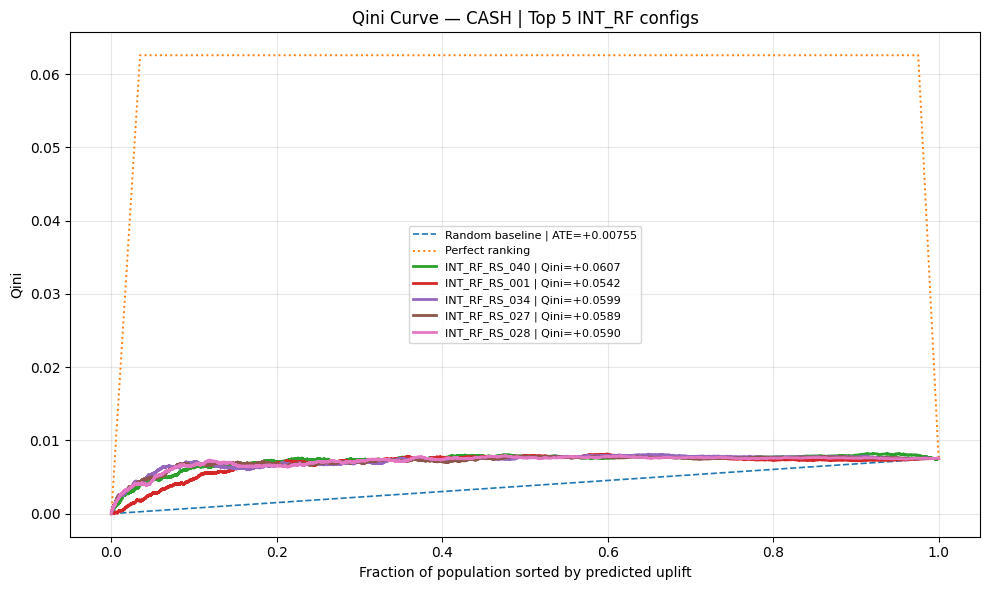

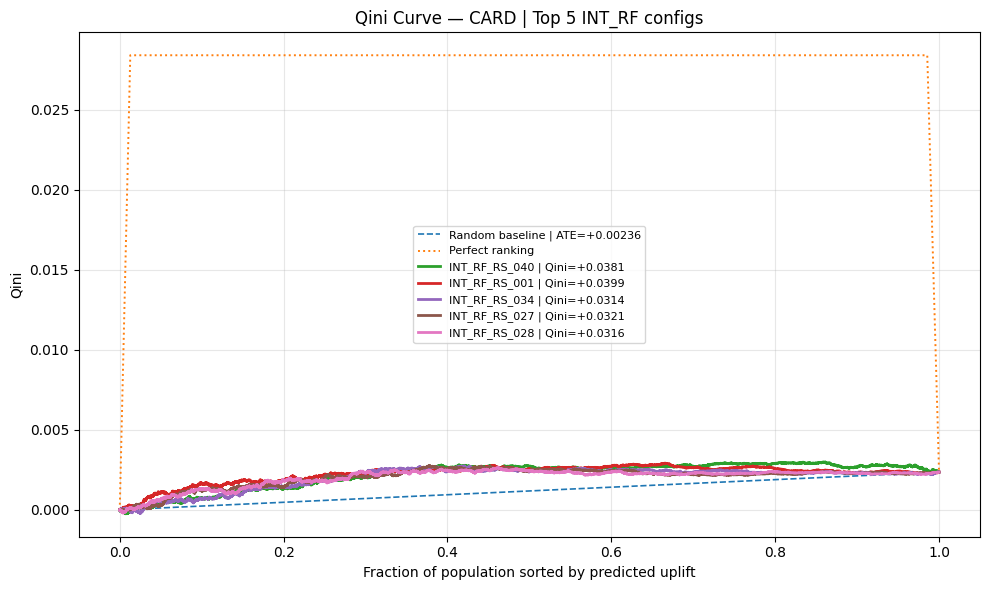

In [12]:
# ============================================================
# 11. QINI CURVES
# ============================================================
def plot_qini_compare(target_name, y, w_event, score_dict, top_models=None):
    if not score_dict:
        print(f"No scores for {target_name}")
        return

    if top_models is not None:
        score_dict = {m: score_dict[m] for m in top_models if m in score_dict}

    plt.figure(figsize=(10, 6))
    xp, qp = qini_curve(y, w_event, oracle_score(y, w_event))
    ate = qp[-1]
    plt.plot([0, 1], [0, ate], "--", linewidth=1.2, label=f"Random baseline | ATE={ate:+.5f}")
    plt.plot(xp, qp, ":", linewidth=1.4, label="Perfect ranking")

    for model_name, score in score_dict.items():
        x, q = qini_curve(y, w_event, score)
        m = qini_metrics(y, w_event, score)
        plt.plot(x, q, linewidth=2, label=f"{model_name} | Qini={m['qini_norm']:+.4f}")

    plt.title(f"Qini Curve — {target_name.upper()} | Top {len(score_dict)} INT_RF configs")
    plt.xlabel("Fraction of population sorted by predicted uplift")
    plt.ylabel("Qini")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


top_models_for_plot = summary.head(PLOT_TOP_N_MODELS)["model"].tolist() if "summary" in globals() and not summary.empty else None
plot_qini_compare("cash", Y_cash, w_cash, scores_oof["cash"], top_models=top_models_for_plot)
plot_qini_compare("card", Y_card, w_card, scores_oof["card"], top_models=top_models_for_plot)


## 8. Export outputs


In [13]:
# ============================================================
# 12. EXPORT OUTPUTS
# ============================================================
def _safe_run_name(text, max_len=80):
    text = "baseline_all_features" if text is None else str(text)
    text = re.sub(r"[^A-Za-z0-9_.-]+", "_", text)
    return text[:max_len].strip("_") or "run"


BASE_OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
if not FEATURE_DROP_BASE_COLS:
    RUN_TAG = "baseline_all_features_int_rf_random_search"
else:
    id_part = "ids_" + "-".join("NA" if i is None else str(i) for i in FEATURE_DROP_IDXS)
    name_part = _safe_run_name("__".join(FEATURE_DROP_BASE_COLS), max_len=100)
    RUN_TAG = f"drop_{id_part}_{name_part}_int_rf_random_search"

OUTPUT_DIR = BASE_OUTPUT_DIR / RUN_TAG
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output dir:", OUTPUT_DIR, flush=True)

summary_path = OUTPUT_DIR / "qini_summary.csv"
summary.to_csv(summary_path, index=False)
print("Saved:", summary_path, flush=True)

fold_path = OUTPUT_DIR / "fold_qini_logs.csv"
fold_qini_logs.to_csv(fold_path, index=False)
print("Saved:", fold_path, flush=True)

fold_mean_path = OUTPUT_DIR / "fold_mean_qini_by_model.csv"
fold_mean_qini_by_model.to_csv(fold_mean_path, index=False)
print("Saved:", fold_mean_path, flush=True)

run_log_df = pd.DataFrame(run_log)
run_log_path = OUTPUT_DIR / "run_log.csv"
run_log_df.to_csv(run_log_path, index=False)
print("Saved:", run_log_path, flush=True)

if "search_results_df" in globals() and not search_results_df.empty:
    search_results_path = OUTPUT_DIR / "int_rf_random_search_results.csv"
    search_results_df.sort_values("Qini_coefficient_total", ascending=False).to_csv(search_results_path, index=False)
    print("Saved:", search_results_path, flush=True)

train_id = make_id_series(feat, id_col=ID_COL)

oof_out = pd.DataFrame()
oof_out[train_id.name] = train_id.values
oof_out["treatment_cash"] = W
oof_out["cash_sign_30d"] = Y_cash
oof_out["card_sign_30d"] = Y_card
oof_out["feature_drop_base_col"] = FEATURE_DROP_BASE_COL
oof_out["feature_drop_col_idx"] = FEATURE_DROP_COL_IDX
oof_out["feature_drop_n_base_cols"] = len(FEATURE_DROP_BASE_COLS)
for name, score in scores_oof["cash"].items():
    oof_out[f"cash_{name}"] = score
for name, score in scores_oof["card"].items():
    oof_out[f"card_{name}"] = score

oof_path = OUTPUT_DIR / "oof_model_scores.csv"
oof_out.to_csv(oof_path, index=False)
print("Saved:", oof_path, flush=True)

if best_model is not None:
    best_config_A = clean_int_rf_config(model_config_map.get(best_model, A if "A" in globals() and A is not None else INT_RF_BASELINE_CONFIG))
    A = dict(best_config_A)

    best_info = {
        "best_model": best_model,
        "metric": "QINI = qini_cash + qini_card",
        "A": A,
        "Qini_coefficient_cash": float(summary.iloc[0]["Qini_coefficient_cash"]),
        "Qini_coefficient_card": float(summary.iloc[0]["Qini_coefficient_card"]),
        "Qini_coefficient_total": float(summary.iloc[0]["Qini_coefficient_total"]),
    }
    best_config_path = OUTPUT_DIR / "best_int_rf_config_A.json"
    with open(best_config_path, "w", encoding="utf-8") as f:
        json.dump(best_info, f, ensure_ascii=False, indent=2)
    print("Saved:", best_config_path, flush=True)

    # In lại A ra Logs ở cuối notebook để dễ copy khi chạy Kaggle background.
    print("\n" + "#" * 120, flush=True)
    print("FINAL A — BEST INT_RF CONFIG TO REPRODUCE", flush=True)
    print("A =", json.dumps(A, sort_keys=True, ensure_ascii=False), flush=True)
    print(f"BEST_MODEL = {best_model}", flush=True)
    print(f"BEST_QINI_CASH  = {best_info['Qini_coefficient_cash']:+.8f}", flush=True)
    print(f"BEST_QINI_CARD  = {best_info['Qini_coefficient_card']:+.8f}", flush=True)
    print(f"BEST_QINI_TOTAL = {best_info['Qini_coefficient_total']:+.8f}", flush=True)
    print("#" * 120 + "\n", flush=True)

    final_train = pd.DataFrame()
    final_train[train_id.name] = train_id.values
    final_train["feature_drop_base_col"] = FEATURE_DROP_BASE_COL
    final_train["feature_drop_col_idx"] = FEATURE_DROP_COL_IDX
    final_train["feature_drop_n_base_cols"] = len(FEATURE_DROP_BASE_COLS)
    final_train["best_model"] = best_model
    final_train["best_config_A_json"] = json.dumps(A, sort_keys=True, ensure_ascii=False)
    final_train["uplift_cash_score"] = scores_oof["cash"][best_model]
    final_train["uplift_card_score"] = scores_oof["card"][best_model]
    final_train["cash_vs_card_score"] = final_train["uplift_cash_score"] - final_train["uplift_card_score"]
    final_train["recommended_product"] = np.where(final_train["cash_vs_card_score"] >= 0, "Cash", "Card")

    final_train_path = OUTPUT_DIR / "final_scores_train.csv"
    final_train.to_csv(final_train_path, index=False)
    print("Saved:", final_train_path, flush=True)

    if X_test is not None and best_model in scores_test["cash"] and best_model in scores_test["card"]:
        submission = pd.DataFrame()
        submission[test_id.name] = test_id.values
        submission["best_model"] = best_model
        submission["best_config_A_json"] = json.dumps(A, sort_keys=True, ensure_ascii=False)
        submission["uplift_cash_score"] = scores_test["cash"][best_model]
        submission["uplift_card_score"] = scores_test["card"][best_model]
        submission["cash_vs_card_score"] = submission["uplift_cash_score"] - submission["uplift_card_score"]
        submission["recommended_product"] = np.where(submission["cash_vs_card_score"] >= 0, "Cash", "Card")

        submission_path = OUTPUT_DIR / "submission.csv"
        submission.to_csv(submission_path, index=False)
        print("Saved:", submission_path, flush=True)
    else:
        print("Skip submission: không có X_test hoặc best_model không có test score.", flush=True)
else:
    print("Skip final score export: không có best_model.", flush=True)

feature_drop_result = {
    "COL_IDX_config": str(COL_IDX),
    "feature_drop_col_idx": FEATURE_DROP_COL_IDX,
    "feature_drop_base_col": FEATURE_DROP_BASE_COL,
    "n_feature_drop_base_cols": len(FEATURE_DROP_BASE_COLS),
    "feature_drop_base_cols": "|".join(FEATURE_DROP_BASE_COLS),
    "n_dropped_train_cols": len(drop_cols_in_feat),
    "dropped_train_cols": "|".join(drop_cols_in_feat),
    "n_features_after_drop": len(FEAT_COLS),
    "best_model": best_model,
    "best_config_A_json": json.dumps(A, sort_keys=True, ensure_ascii=False) if "A" in globals() and A is not None else None,
}
if best_model is not None:
    best_row = summary.iloc[0].to_dict()
    feature_drop_result.update({
        "best_Qini_coefficient_cash": best_row["Qini_coefficient_cash"],
        "best_Qini_coefficient_card": best_row["Qini_coefficient_card"],
        "best_Qini_coefficient_total": best_row["Qini_coefficient_total"],
    })

feature_drop_result_path = OUTPUT_DIR / "feature_drop_result.csv"
pd.DataFrame([feature_drop_result]).to_csv(feature_drop_result_path, index=False)
print("Saved:", feature_drop_result_path, flush=True)


Output dir: /kaggle/working/baseline_all_features_int_rf_random_search
Saved: /kaggle/working/baseline_all_features_int_rf_random_search/qini_summary.csv
Saved: /kaggle/working/baseline_all_features_int_rf_random_search/fold_qini_logs.csv
Saved: /kaggle/working/baseline_all_features_int_rf_random_search/fold_mean_qini_by_model.csv
Saved: /kaggle/working/baseline_all_features_int_rf_random_search/run_log.csv
Saved: /kaggle/working/baseline_all_features_int_rf_random_search/int_rf_random_search_results.csv
Saved: /kaggle/working/baseline_all_features_int_rf_random_search/oof_model_scores.csv
Saved: /kaggle/working/baseline_all_features_int_rf_random_search/best_int_rf_config_A.json

########################################################################################################################
FINAL A — BEST INT_RF CONFIG TO REPRODUCE
A = {"bootstrap": true, "class_weight": null, "criterion": "entropy", "max_depth": 6, "max_features": 0.75, "max_samples": 0.7, "min_samples_leaf":

## 9. Cách đọc kết quả

Notebook này chỉ train **INT_RF** và search nhiều configuration của INT_RF.

Các thông tin quan trọng trong Kaggle Logs:

- Mỗi candidate sẽ in ra:
  - `CONFIG_JSON`
  - `QINI_CASH`
  - `QINI_CARD`
  - `QINI_TOTAL`

- Configuration tốt nhất được in rõ ở cuối Logs dưới dạng:

```python
A = {...}
```

Copy dictionary `A` này để tái tạo lại model tốt nhất.

Các file quan trọng sau khi chạy:

- `qini_summary.csv`: Qini OOF của toàn bộ cấu hình INT_RF đã thử.
- `int_rf_random_search_results.csv`: bảng random search, gồm config và QINI.
- `best_int_rf_config_A.json`: cấu hình tốt nhất A + QINI tương ứng.
- `fold_qini_logs.csv`: Qini từng fold cho từng configuration.
- `fold_mean_qini_by_model.csv`: Qini trung bình 5 fold.
- `feature_drop_result.csv`: file gọn nhất để so sánh các lần drop feature.
- `final_scores_train.csv`: score uplift Cash/Card và khuyến nghị Cash/Card trên train.
- `submission.csv`: chỉ tạo nếu notebook tìm thấy test feature đã clean/one-hot tương thích với `df_feature.csv`.
